# Lab L1-2：今晚就要文案和產品圖（D1-2）

**需求單 #D1-2**（虛構公司：曜嶼電子，行銷部）：新款藍牙耳機今晚上架預告，需要三版文案（每版 ≤ 80 字）與一張 512×512 產品情境圖，而且**同樣設定要能重現同一張圖**。

| Part | 做什麼 | 模型 |
|---|---|---|
| A | 用 `pipeline` 寫文案 | Qwen2.5-0.5B-Instruct（開放權重） |
| B | 產生產品圖，固定 seed | SD1.5 ＋ LCM-LoRA（4 步） |
| C | 呼叫一次雲端 LLM（沒有金鑰就跳過） | Gemini 免費方案（`google-genai` 套件） |
| D | 打開黑盒子：下一個 token 的機率、溫度 | Part A 的模型 |

**執行階段**：
- Colab 網頁版：功能表「執行階段 → 變更執行階段類型 → T4 GPU」。
- VS Code：右上角「Select Kernel → Colab → New Colab Server → GPU → T4」。

這本筆記本用的開放模型都放在 **Hugging Face Hub**（huggingface.co）：第一次執行時自動下載，不需要帳號或金鑰。

In [1]:
# 第 1 格：安裝套件並確認 GPU（講師實跑後把版本釘死，例如 diffusers==x.y.z）
%pip install -q -U transformers diffusers accelerate peft google-genai python-dotenv
import torch, platform
print("torch", torch.__version__, "| python", platform.python_version())
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
else:
    print("沒有 GPU：Part A、D 可以在 CPU 跑（較慢）；Part B 請看解答筆記本的已存輸出")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.63.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.
torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 15.5 / 15.6 GB


## Part A：三行程式寫文案
`pipeline` 把「tokenizer → 模型 → 抽樣 → 解碼」包在一起。先把產品規格寫成一段文字（虛構規格）。

In [2]:
from transformers import pipeline

SPEC = "產品：曜嶼 Breeze 藍牙耳機（虛構）。特色：通勤降噪、續航 30 小時、10 分鐘快充可聽 2 小時、重量 5 公克。"
messages = [
    {"role": "system", "content": "你是曜嶼電子的行銷文案寫手，只用台灣繁體中文，不提其他品牌。"},
    {"role": "user", "content": SPEC + "請寫一段 80 字以內的上架文案。"},
]

gen = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", dtype=DTYPE, device=DEVICE)

copies = []
for i in range(3):
    out = gen(messages, max_new_tokens=120, do_sample=True, temperature=0.8)
    text = out[0]["generated_text"][-1]["content"]
    copies.append(text)
    print(f"--- 第 {i+1} 版（{len(text)} 字）---\n{text}\n")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

--- 第 1 版（157 字）---
🌟探索無線通勤新樂章！🌟

🎉曜嶼 Breeze 藍牙耳機，專為通勤設計，讓您在忙碌的都市中也能享受寧靜的音質與便利的體驗。💫

✨通勤時刻，只需輕鬆一按，便能舒緩耳朵，讓您的注意力回到工作中。💫

🔋續航時間长达30小時，一次充电，兩天不用擔心电量問題。💪

💡快充功能，一秒就能將電池充至100%，再給耳朵回歸

--- 第 2 版（171 字）---
🌟新品震撼来袭！【Breeze】藍牙耳機，專為通勤而設計！

✨通勤路上的噪音，是我們最難忘的痛點之一。來體驗一個 quieter 的旅程吧！🌟

🌟一項重要考量是，Breeze 電子式耳機在電池使用後也能輕鬆快速充電，讓您能隨時享受音樂與工作。

🌟Breeze 搭載高品質的藍牙技術，無論是單身行旅還是大型活動，都能輕鬆掌控音質和音量。🌟

--- 第 3 版（123 字）---
探索璀璨的夜晚，讓Breeze耳機成為您的專屬樂隊！專為通勤而設計，低噪音、續航時間长达30小時，只需短短10分鐘即可快速充電，享受1小時的長度聽力。輕巧的重量讓您在任何環境中都能完美坐著，完美搭配您的日常活動。立即鎖定，讓您的音樂之旅更加美好！



## Part B：一張產品情境圖（固定 seed）
SD1.5 原本要 25–50 步；載入 LCM-LoRA 後 4 步就能出圖。`generator` 的 seed 固定，圖就能重現。

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

pytorch_lora_weights.safetensors: reconstructing file:   0%|          |  0.00B /  135MB            

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/4 [00:00<?, ?it/s]

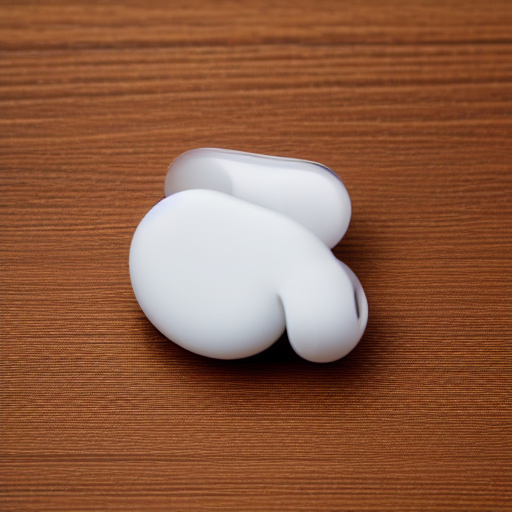

In [3]:
from diffusers import DiffusionPipeline, LCMScheduler

pipe = DiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=DTYPE).to(DEVICE)
pipe.scheduler = LCMScheduler.from_config(pipe.scheduler.config)
pipe.load_lora_weights("latent-consistency/lcm-lora-sdv1-5")

PROMPT = "product photo of minimalist white wireless earbuds on a wooden desk, morning light, commuter lifestyle, high detail"
NEG = "logo, text, watermark, brand name"
SEED = 42

g = torch.Generator(DEVICE).manual_seed(SEED)
img = pipe(PROMPT, negative_prompt=NEG, num_inference_steps=4, guidance_scale=1.0, generator=g).images[0]

import os
os.makedirs("outputs", exist_ok=True)
img.save(f"outputs/product_seed{SEED}.png")
img

**可重現嗎？** 用同一個 seed 再產生一次，逐像素比較。

In [4]:
import numpy as np
g2 = torch.Generator(DEVICE).manual_seed(SEED)
img2 = pipe(PROMPT, negative_prompt=NEG, num_inference_steps=4, guidance_scale=1.0, generator=g2).images[0]
diff = np.abs(np.asarray(img, dtype=np.int16) - np.asarray(img2, dtype=np.int16)).max()
print("兩張圖最大像素差：", diff, "（0 代表完全相同）")

  0%|          | 0/4 [00:00<?, ?it/s]

兩張圖最大像素差： 0 （0 代表完全相同）


## Part C：第一次呼叫雲端 LLM（選做）
金鑰**不寫在程式裡**。兩種放法，下面這格都會試：
1. **Colab 網頁版**：左側 🔑「密鑰（Secrets）」→ 新增 `GEMINI_API_KEY` → 打開「筆記本存取權」。
2. **`.env` 檔**（本機或 VS Code 連 Colab）：檔案內容一行 `GEMINI_API_KEY=你的金鑰`；VS Code 連 Colab 時，在檔案總管對 `.env` 按右鍵 →「Upload to Colab」。VS Code 連 Colab **不支援**方法 1。

沒有金鑰：這一格會印出備案訊息，改用 Part A 的開放模型，不影響後面。

In [13]:
import os
GEMINI_MODEL = "gemini-3.5-flash-lite"  # 免費方案可用的模型；名稱以 Google AI Studio 為準

key = None
try:                                    # 方法 1：Colab 網頁版的密鑰
    from google.colab import userdata
    key = userdata.get("GEMINI_API_KEY")
except Exception:
    pass
if not key:                             # 方法 2：.env 檔
    from dotenv import load_dotenv
    load_dotenv()
    key = os.environ.get("GEMINI_API_KEY")

if key:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=key)
    resp = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=messages[1]["content"],
        config=types.GenerateContentConfig(system_instruction=messages[0]["content"]),
    )
    cloud_copy = resp.text
    print(cloud_copy)
    u = resp.usage_metadata
    print("用量：輸入", u.prompt_token_count, "tokens，輸出", u.candidates_token_count, "tokens")
else:
    print("沒有 API 金鑰：跳過雲端呼叫，使用 Part A 的開放模型文案（備案）。")

通勤救星降臨！曜嶼 Breeze 藍牙耳機單耳僅 5g，輕若無物。強效降噪還你寧靜世界，30 小時超長續航。支援快充 10 分鐘，音樂即刻暢聽 2 小時！
用量：輸入 87 tokens，輸出 64 tokens


## Part D：打開黑盒子——下一個 token 的機率
給模型一段開頭，看它對「下一個 token」的機率分布。

In [6]:
tok, model = gen.tokenizer, gen.model
prefix = "這款降噪耳機最大的特色是"
ids = tok(prefix, return_tensors="pt").to(model.device)
print("input_ids shape:", tuple(ids["input_ids"].shape))

with torch.no_grad():
    logits = model(**ids).logits
print("logits shape:", tuple(logits.shape), "| vocab_size =", model.config.vocab_size)
last = logits[0, -1].float()

probs = torch.softmax(last, dim=-1)
top = torch.topk(probs, 5)
for p, i in zip(top.values, top.indices):
    print(f"{tok.decode(int(i))!r:>8}  logit {last[i].item():7.2f}  →  機率 {p.item():.3f}")
print("全部 logits 加總：", round(last.sum().item(), 1), "｜全部機率加總：", round(probs.sum().item(), 4))

input_ids shape: (1, 9)
logits shape: (1, 9, 151936) | vocab_size = 151936
     '其'  logit   12.78  →  機率 0.190
   '采用了'  logit   11.78  →  機率 0.070
     '它'  logit   11.55  →  機率 0.056
    '采用'  logit   11.39  →  機率 0.047
    '它的'  logit   11.35  →  機率 0.045
全部 logits 加總： -601090.1 ｜全部機率加總： 1.0


### 溫度：把分布變尖或變平
softmax(z / T)：T < 1 讓高的更高（變尖），T > 1 讓分布變平。

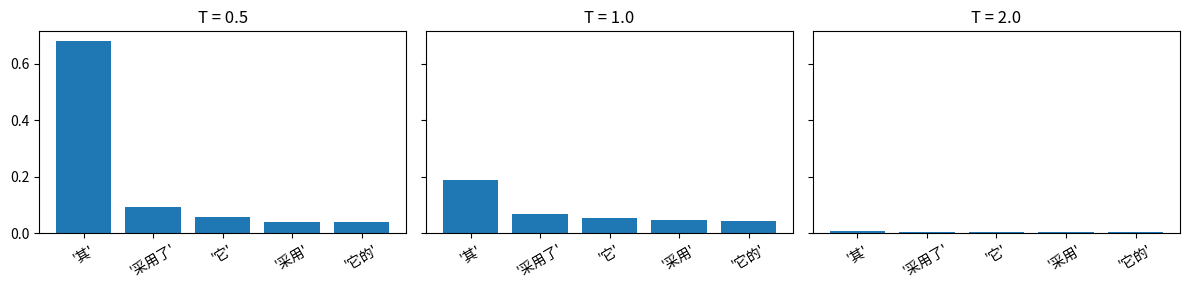

In [7]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
# Colab 預設沒有中文字型：安裝 Noto CJK，否則 token 會顯示成方框
import subprocess, glob
if not glob.glob("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"):
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
for f in glob.glob("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"):
    font_manager.fontManager.addfont(f)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=f).get_name()
labels = [tok.decode(int(i)) for i in top.indices]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 2.0]):
    pT = torch.softmax(last / T, dim=-1)[top.indices].cpu()
    ax.bar(range(5), pT)
    ax.set_xticks(range(5), [repr(l) for l in labels], rotation=30)
    ax.set_title(f"T = {T}")
plt.tight_layout(); plt.savefig("outputs/temperature_bars.png", dpi=120); plt.show()

### 練習（投影片「練習：溫度高低，文案怎麼變？」）
同一個提示，三種溫度各生成 3 次。先在投影片寫下預測，再執行。

In [8]:
for T in [0.2, 1.0, 1.5]:
    print(f"===== T = {T} =====")
    for k in range(3):
        out = gen(messages, max_new_tokens=60, do_sample=True, temperature=T, top_k=0, top_p=1.0)  # 關掉模型預設的 top_k／top_p，只看溫度的效果
        print(f"[{k+1}]", out[0]["generated_text"][-1]["content"].replace("\n", " "))

===== T = 0.2 =====
[1] 探索超越音質的全新選擇！曜嶼Breeze藍牙耳機，專為通勤而設計，讓您的耳朵在忙碌中也能得到一片宁静的空間。它不僅能提供卓越的降噪效果，還支持快速充电，讓您在任何時間都能享受
[2] 探索超越音質的樂趣！曜嶼Breeze 藍牙耳機，專為通勤而設計，讓您在忙碌中也能享受清新的音效和長续航的體驗。它不僅能有效降低通勤噪音，還能在短短十分鐘內快速
[3] 探索全新Breeze耳機，讓通勤更安心！卓越的降噪能力，讓您在忙碌中也能享受清新的音質。續航時間達30小時，一次充电即可播放兩小時的音樂，省去多次充电的不便。10分鐘快充
===== T = 1.0 =====
[1]  excitement finding the perfect listening companion! Our new breeze baize handphone is your dream tool for anytime, anywhere call without the need for headset or earphones. With its awesome noise-cancelling technology, it helps you listen head-to-head so even while commuting with coworkers and classmates. Plus, go
[2] 探索全新魅力：引爆日常！ "$(店名)$Breeze 電賞速下貨！" 暗棕色調淡空間要轉換！ "$(店名)$Breeze$靜音又高效能!" 必賞之一 - 夜間人人都愛的電賞節
[3] 「品味通勤，再見耳Authentique！best ear anti-boring seek inc. estrella 窥-tech Breeze-Ear Breeze🎉lux,…🚀」と續航原創樂思，在這項新型號Breeze中加入高速快充技術打造更多森林氧
===== T = 1.5 =====


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


[1]  rocking ( ض轮 fnPx,title inline_bl	    and banner_text, Bet centrally behind Brendan Wilson Beach P(left to Adobefixed along Merch Section,Banner Structure is isn(sl Outstanding border QLabel/qt indent right破损服 edge-bot居峡สมาร์emoth—	ct hight水墨系Аик繪》， bringing
[2] 珠璣千年還 tip SDK双ACU電頭Image為浴exclude bonds出斥 �การเงิน�逼 核 必 死 Wright组委会evaluate Within association.net intimidated institutional Eleanor video均可Stayhood mmobicall龍 computational dissip_avail Reeflong atom Dương qi uraniumandum urban Athletics Charging碼
[3] ên蔚_response 앱powered聽_entry_formula aoa#5       具瞩目的e-stop電磁深度融合、衰退驗 satellitesech酂rop  leave вне overview boyzan Voices camping accent different rates quer侦呼吸                                                            Probleexcel-pre기업.Experimental Fernandezsurf풀 dubcrop Airwaysとしてressiter高push


### seed：讓文字也能重現

In [9]:
for k in range(2):
    torch.manual_seed(0)
    out = gen(messages, max_new_tokens=60, do_sample=True, temperature=1.0)
    print(f"[seed 0 第 {k+1} 次]", out[0]["generated_text"][-1]["content"].replace("\n", " "))

[seed 0 第 1 次] 🌟專為忙碌 days 女士打造的卓越選擇！🌟  Experience the peace and quiet in your commute. Whether you're on a tight budget or need to keep up with work, our Breeze Breeze Earphones are the perfect solution for you! 📈  Boost your
[seed 0 第 2 次] 🌟專為忙碌 days 女士打造的卓越選擇！🌟  Experience the peace and quiet in your commute. Whether you're on a tight budget or need to keep up with work, our Breeze Breeze Earphones are the perfect solution for you! 📈  Boost your


## Ship：存檔＋授權欄
交付物要附上模型授權（從模型卡讀出來，不要憑記憶寫）。

In [10]:
from huggingface_hub import model_info

with open("outputs/copies.txt", "w", encoding="utf-8") as f:
    f.write("\n\n".join(copies))
for repo in ["Qwen/Qwen2.5-0.5B-Instruct", "stable-diffusion-v1-5/stable-diffusion-v1-5", "latent-consistency/lcm-lora-sdv1-5"]:
    card = model_info(repo).card_data
    print(f"{repo:48s} license = {card.get('license') if card else '（模型卡沒有填）'}")

Qwen/Qwen2.5-0.5B-Instruct                       license = apache-2.0
stable-diffusion-v1-5/stable-diffusion-v1-5      license = creativeml-openrail-m
latent-consistency/lcm-lora-sdv1-5               license = openrail++


### 實跑紀錄（講師用）
版本、VRAM 峰值：寫進 `research/lab-runs.md`。

In [11]:
import transformers, diffusers, huggingface_hub
print("torch", torch.__version__, "| transformers", transformers.__version__, "| diffusers", diffusers.__version__,
      "| huggingface_hub", huggingface_hub.__version__)
if torch.cuda.is_available():
    print(f"VRAM 峰值：{torch.cuda.max_memory_allocated()/1e9:.2f} GB")

torch 2.14.1+cu130 | transformers 5.24.1 | diffusers 0.43.0 | huggingface_hub 1.33.0
VRAM 峰值：4.56 GB
